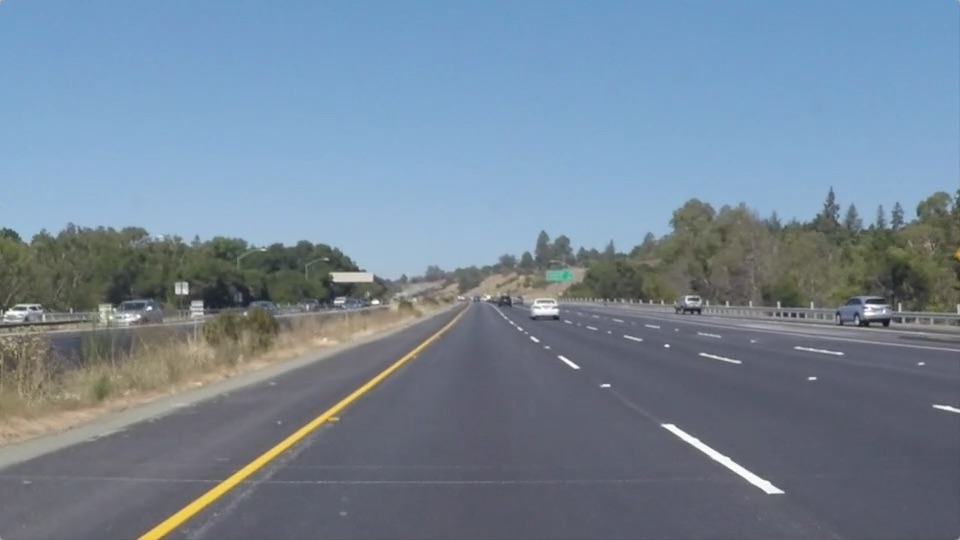

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import numpy as np

repo_dir = next(
    path
    for path in (Path("."), Path(".."), Path("../.."), Path("../../.."))
    if (path / "实践1" / "outer1.png").is_file()
)

# 读取图像，转换为numpy数组

image = Image.open(repo_dir / "实践1" / "outer1.png")
image = image.convert("RGB")
image_array = np.array(image)
display(image)

In [5]:
# 打印数组基本信息
# shape: (540, 960, 3) -> 高，宽，通道数
# RGB: [181 197 213] -> [0, 0]处像素三个通道分量的强度
print("shape:", image_array.shape)
print("dtype:", image_array.dtype)
print("max:", image_array.max())
print("min:", image_array.min())
print("RGB:", image_array[0, 0])

shape: (540, 960, 3)
dtype: uint8
max: 255
min: 16
RGB: [181 197 213]


In [6]:
# 装换为tensor，输出基本信息
# 将HWC（高宽通道表示顺序）变为CHW（通道高宽表示顺序）
image_tensor = torch.from_numpy(image_array)
image_tensor = image_tensor.permute(2,0,1)
print("shape:", image_tensor.shape)
print("dtype:", image_tensor.dtype)
print("max:", image_tensor.max().item())
print("min:", image_tensor.min().item())
print("RGB:", image_tensor[:, 0, 0])

shape: torch.Size([3, 540, 960])
dtype: torch.uint8
max: 255
min: 16
RGB: tensor([181, 197, 213], dtype=torch.uint8)


In [7]:
# 图像缩放与格式转换，以便模型训练
image_tensor = image_tensor.float() / 255.0
print("dtype:", image_tensor.dtype)
print("RGB:", image_tensor[:, 0, 0])

dtype: torch.float32
RGB: tensor([0.7098, 0.7725, 0.8353])
